# Классификация изображений: кошки и собаки

В этой работе мы обучим классификатор `cat` / `dog`, сравним модели и сохраним выбранную модель в ONNX.

1. [Собрать 100 фото кошек и 100 фото собак и сохранить первую версию датасета в DVC](#photos).
2. [Расширить набор до 400 изображений](#versions).
3. [Проверить и исправить метки](#labels).
4. [Обучить две модели на финальном датасете и сравнить их в MLflow](#training).
5. [Сравнить модели ONNX FP32 и INT8 на CPU](#quantization).

## Начинаем с чистой рабочей папки

Удаляем `data/`, если она уже есть. Вместе с ней удаляются локальные коммиты Git, черновик разметки и результаты обучения. Хранилище DVC находится рядом, в `dvc_remote/`.

In [1]:
from pathlib import Path
import shutil

data = Path("data")
if data.exists():
    shutil.rmtree(data)

<a id="photos"></a>

## 1. Сбор 200 фотографий для первой версии датасета

Набор из 100 фотографий кошек и 100 фотографий собак назовём **v1**. Позже добавим ещё по 100 фотографий каждого класса и сохраним расширенный набор как **v2**.

- Фотографии кошек загружаем из [CATAAS](https://cataas.com/).
- Фотографии собак загружаем из [Dog CEO Dog API](https://dog.ceo/dog-api/).

Снимки сохраняем как JPEG в папке `images/`. Для каждого снимка в `labels.json` записываем имя файла (`name`), класс `cat` или `dog` (`label`) и ссылку на источник (`url`).

Задаём `dataset_dir`, путь к рабочей папке датасета. В ней будем собирать фотографии, дополнять набор и проверять метки. Этот путь одинаков для всех версий. Функции ниже читают и записывают `labels.json`.

In [2]:
import json

dataset_dir = data / "dataset"
dataset_pointer = data / "dataset.dvc"

def read_labels(folder):
    return json.loads((folder / "labels.json").read_text(encoding="utf-8"))

def write_labels(folder, rows):
    (folder / "labels.json").write_text(json.dumps(rows, indent=2), encoding="utf-8")

Создаём папку `images/` внутри `dataset_dir`. Список `labels` пока пуст. После каждого успешного скачивания добавим в него имя файла, класс и ссылку на фото.

In [3]:
(dataset_dir / "images").mkdir(parents=True)
labels = []

Запрашиваем идентификаторы кошек у CATAAS страницами по 100 записей. Из каждого идентификатора получаем адрес отдельного снимка. Генератор запрашивает следующую страницу по мере необходимости.

In [4]:
import requests

def cat_urls():
    for skip in range(0, 1000, 100):
        page = requests.get("https://cataas.com/api/cats", params={"limit": 100, "skip": skip}, timeout=20)
        page.raise_for_status()
        cats = page.json()
        if not cats:
            return
        for cat in cats:
            yield "https://cataas.com/cat/" + cat["id"]

Dog CEO возвращает ссылки по породам. Перемешиваем список пород с фиксированным seed и берём до восьми адресов от каждой, чтобы в набор попали разные породы.

In [5]:
import random

def dog_urls():
    page = requests.get("https://dog.ceo/api/breeds/list/all", timeout=20)
    page.raise_for_status()
    breeds = list(page.json()["message"])
    random.Random(42).shuffle(breeds)
    for breed in breeds:
        page = requests.get(f"https://dog.ceo/api/breed/{breed}/images", timeout=20)
        page.raise_for_status()
        yield from page.json()["message"][:8]

Скачиваем один снимок по URL и сохраняем его как JPEG. При параллельной загрузке готовые JPEG сначала лежат в буферах в памяти. Если снимок недоступен или ведёт на анимацию, пробуем следующую ссылку.

In [6]:
from io import BytesIO
import time
from PIL import Image, ImageOps

def download_photo(url, path):
    """Сохранить JPEG по указанному пути или в буфере. Если снимок недоступен, вернуть False."""
    time.sleep(0.25)
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        with Image.open(BytesIO(response.content)) as image:
            if getattr(image, "is_animated", False):
                return False
            photo = ImageOps.exif_transpose(image).convert("RGB")
    except (requests.RequestException, OSError):
        return False
    photo.save(path, "JPEG")
    return True

Скачиваем до четырёх снимков одновременно. После загрузки очередной группы сохраняем удачные снимки в порядке ссылок. Так имена файлов идут подряд даже при неудачных запросах. Полоска `tqdm` продвигается после записи каждого JPEG.

In [7]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

def collect(folder, rows, label, urls, target, workers=4):
    count = sum(row["label"] == label for row in rows)
    used = {row["url"] for row in rows}
    urls = iter(urls)

    with ThreadPoolExecutor(max_workers=workers) as pool, tqdm(
        total=target, initial=count, desc=label, unit="фото"
    ) as progress:
        while count < target:
            batch_size = min(workers, target - count)
            batch = []
            for url in urls:
                if url in used or url in batch:
                    continue
                batch.append(url)
                if len(batch) == batch_size:
                    break
            if not batch:
                break

            buffers = [BytesIO() for _ in batch]
            results = pool.map(download_photo, batch, buffers)
            for url, buffer, downloaded in zip(batch, buffers, results):
                if not downloaded:
                    continue

                name = f"{label}_{count + 1:03d}.jpg"
                (folder / "images" / name).write_bytes(buffer.getvalue())
                rows.append({"name": name, "label": label, "url": url})
                used.add(url)
                count += 1
                progress.update()

    if count < target:
        raise RuntimeError(f"Получилось {count} фото класса {label}, нужно {target}")

Галерея показывает до восьми фотографий. Имена файлов помогают найти снимки в датасете.

In [8]:
import matplotlib.pyplot as plt
from math import ceil

def gallery(folder, rows, title=""):
    examples = rows[:8]
    columns = min(4, len(examples))
    lines = ceil(len(examples) / columns)
    fig, axes = plt.subplots(lines, columns, figsize=(11, 3.3 * lines),
                             squeeze=False, layout="constrained")
    for ax in axes.flat:
        ax.axis("off")
    for ax, row in zip(axes.flat, examples):
        with Image.open(folder / row["name"]) as image:
            ax.imshow(image)
        ax.set_title(row.get("caption", row["name"]), fontsize=10)
    if title:
        fig.suptitle(title, fontsize=14)
    plt.show()

Скачиваем 100 фотографий кошек из CATAAS.

In [9]:
collect(dataset_dir, labels, "cat", cat_urls(), 100)

cat:   0%|          | 0/100 [00:00<?, ?фото/s]

Скачиваем 100 фотографий собак из Dog CEO. Префиксы `cat_` и `dog_` позволяют хранить снимки обоих классов в одной папке.

In [10]:
collect(dataset_dir, labels, "dog", dog_urls(), 100)

dog:   0%|          | 0/100 [00:00<?, ?фото/s]

Сохраняем список из 200 записей в `labels.json` рядом с папкой `images/`.

In [11]:
write_labels(dataset_dir, labels)

<a id="dvc-data"></a>

### Настройка Git и DVC

В папке `data/` создаём Git-репозиторий для проекта. Для его коммитов задаём локальное имя и адрес автора.

In [12]:
!git -C data init -b main
!git -C data config --local user.name 'Dolotov Evgeniy'
!git -C data config --local user.email dolotov.evgeniy@gmail.com

Initialized empty Git repository in ./data/.git/


Запускаем `dvc init` в Git-репозитории. Git будет хранить указатель `dataset.dvc`, а DVC будет хранить фотографии и разметку.

In [13]:
!cd data && dvc init

Initialized DVC repository.

You can now commit the changes to git.

What's next?
------------
- Check out the documentation: <https://dvc.org/doc>
- Get help and share ideas: <https://dvc.org/chat>
- Star us on GitHub: <https://github.com/treeverse/dvc>


Создаём рядом с проектом папку `dvc_remote/` и подключаем её под именем `dataset-storage`. Флаг `-d` выбирает это хранилище по умолчанию для `dvc push` и `dvc pull`.

In [14]:
Path("dvc_remote").mkdir(exist_ok=True)

!cd data && dvc remote add -d dataset-storage ../dvc_remote

Setting 'dataset-storage' as a default remote.


Проверяем результат командой `dvc remote list`. В строке `dataset-storage` должны появиться путь к папке и пометка `(default)`.

In [15]:
!cd data && dvc remote list

dataset-storage 
./dvc_remote        
(default)


Показываем восемь фотографий кошек и одну запись из разметки.

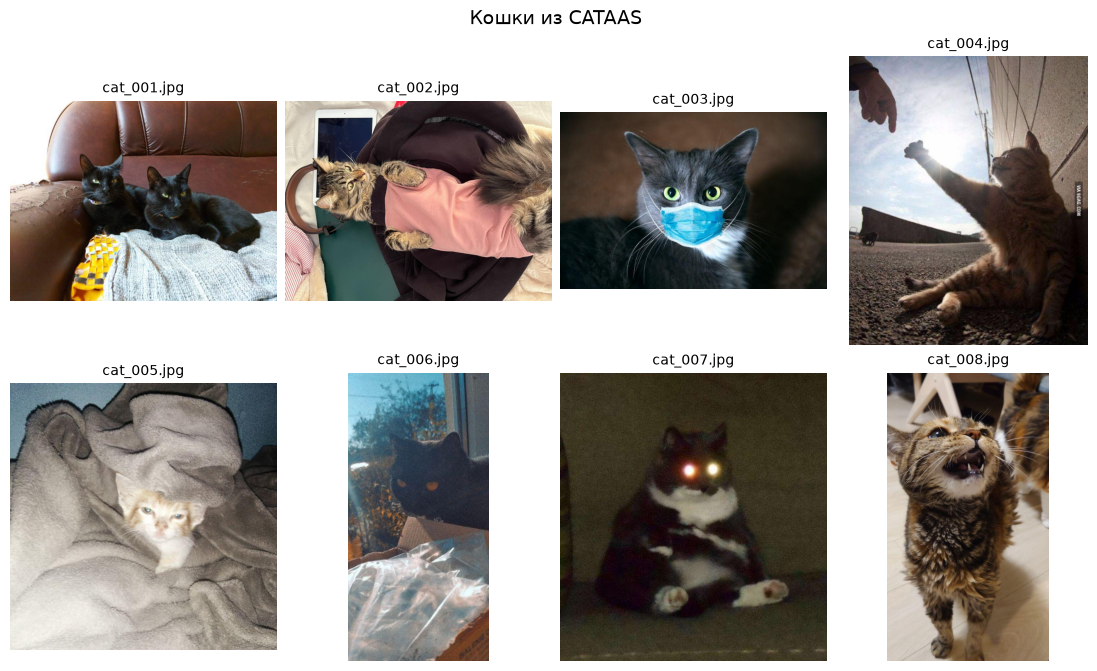

{
  "name": "cat_001.jpg",
  "label": "cat",
  "url": "https://cataas.com/cat/04eEQhDfAL8l5nt3"
}


In [16]:
cats = [row for row in labels if row["label"] == "cat"]
gallery(dataset_dir / "images", cats, "Кошки из CATAAS")
print(json.dumps(cats[0], ensure_ascii=False, indent=2))

Показываем восемь фотографий собак и одну запись из разметки.

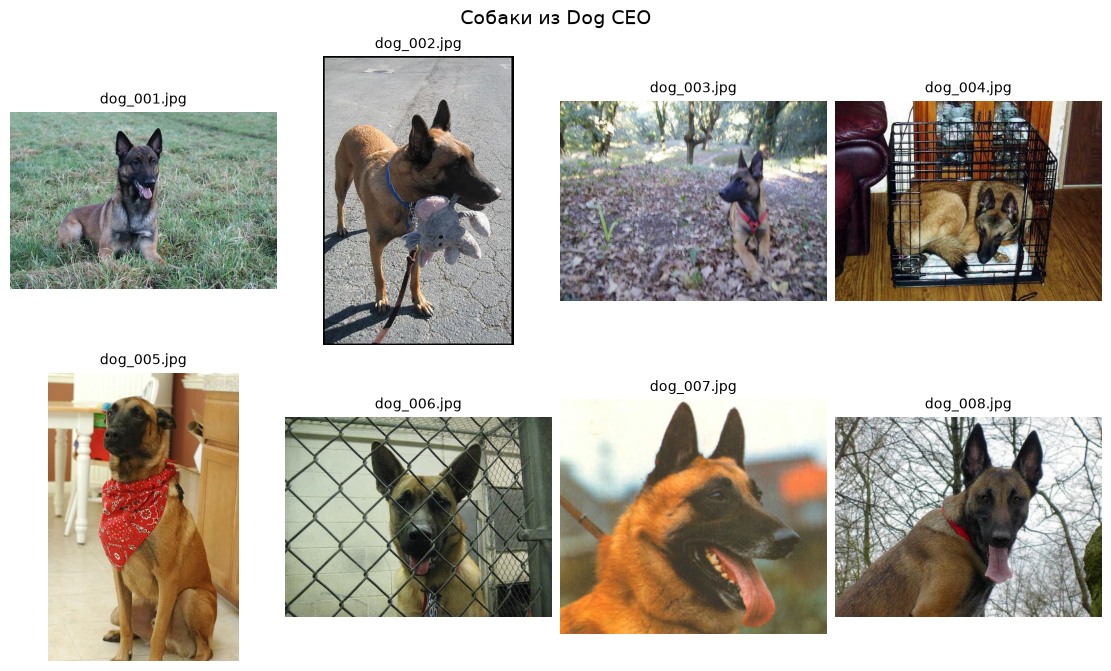

{
  "name": "dog_001.jpg",
  "label": "dog",
  "url": "https://images.dog.ceo/breeds/malinois/n02105162_4120.jpg"
}


In [17]:
dogs = [row for row in labels if row["label"] == "dog"]
gallery(dataset_dir / "images", dogs, "Собаки из Dog CEO")
print(json.dumps(dogs[0], ensure_ascii=False, indent=2))

### Сохраняем первую версию датасета в DVC

Команда `dvc add dataset` кладёт фотографии и разметку в локальный кеш DVC. Она записывает в `dataset.dvc` указатель на это содержимое.

In [18]:
!cd data && dvc add dataset

⠋ Checking graph
!

Adding...                                                                      
!


                                                                               
!
  0% Checking cache in '/home/dolotov-e/Documents/.cats-dogs-benchmark-check-mf
                                                                               
!
  0%|          |Adding dataset to cache            0/201 [00:00<?,     ?file/s]


!
Checking out ./data
100% Adding...|███████████████████████████████████████|1/1 [00:00,  5.34file/s]

To track the changes with git, run:

	git add dataset.dvc .gitignore

To enable auto staging, run:

	dvc config core.autostage true


Команда `dvc push dataset.dvc` переносит содержимое из локального кеша в `dvc_remote/`. Это позволит позже восстановить v1.

In [19]:
!cd data && dvc push dataset.dvc

Pushing


!
  0% Querying remote cache|                         |0/1 [00:00<?,    ?files/s]
                                                                               
!
  0% Checking cache in '/home/dolotov-e/Documents/.cats-dogs-benchmark-check-mf
                                                                               
!
  0% Checking cache in '/home/dolotov-e/Documents/.cats-dogs-benchmark-check-mf
                                                                               
!
  0%|          |Pushing to local                     0/2 [00:00<?,     ?file/s]


Pushing
2 files pushed


Открываем `dataset.dvc`. Поле `path` указывает на рабочую папку, `md5` содержит идентификатор версии, а `nfiles` показывает общее число файлов. Для v1 ожидаем 201 файл (200 JPEG и `labels.json`).

In [20]:
print(dataset_pointer.read_text())

outs:
- md5: 175fac7b2a529a65bd71789f88cd9053.dir
  size: 16914804
  nfiles: 201
  hash: md5
  path: dataset



Сохраняем указатель и настройки DVC в коммите Git. Тег `dataset-v1` даёт этому коммиту имя, по которому можно восстановить первый набор.

In [21]:
!git -C data add .dvc/.gitignore .dvc/config .dvcignore .gitignore dataset.dvc
!git -C data commit -m "Сохраняем датасет v1" && git -C data tag dataset-v1

[main (root-commit) 48e05b8] Сохраняем датасет v1
 5 files changed, 17 insertions(+)
 create mode 100644 .dvc/.gitignore
 create mode 100644 .dvc/config
 create mode 100644 .dvcignore
 create mode 100644 .gitignore
 create mode 100644 dataset.dvc


<a id="versions"></a>

## 2. Создание второй версии датасета из 400 фотографий

Добавляем по 100 фотографий кошек и собак в ту же папку `dataset/`. После сохранения пометим второй коммит тегом `dataset-v2`.

Читаем разметку v2 и добираем фотографии кошек. Останавливаемся, когда в списке будет 200 кошек.

In [22]:
extended = read_labels(dataset_dir)
collect(dataset_dir, extended, "cat", cat_urls(), 200)

cat:  50%|#####     | 100/200 [00:00<?, ?фото/s]

Теперь добираем фотографии собак до 200. Записи о них попадают в тот же список разметки.

In [23]:
collect(dataset_dir, extended, "dog", dog_urls(), 200)

dog:  50%|#####     | 100/200 [00:00<?, ?фото/s]

Показываем по четыре новых снимка каждого класса. Снимки кошек в первом ряду, снимки собак во втором.

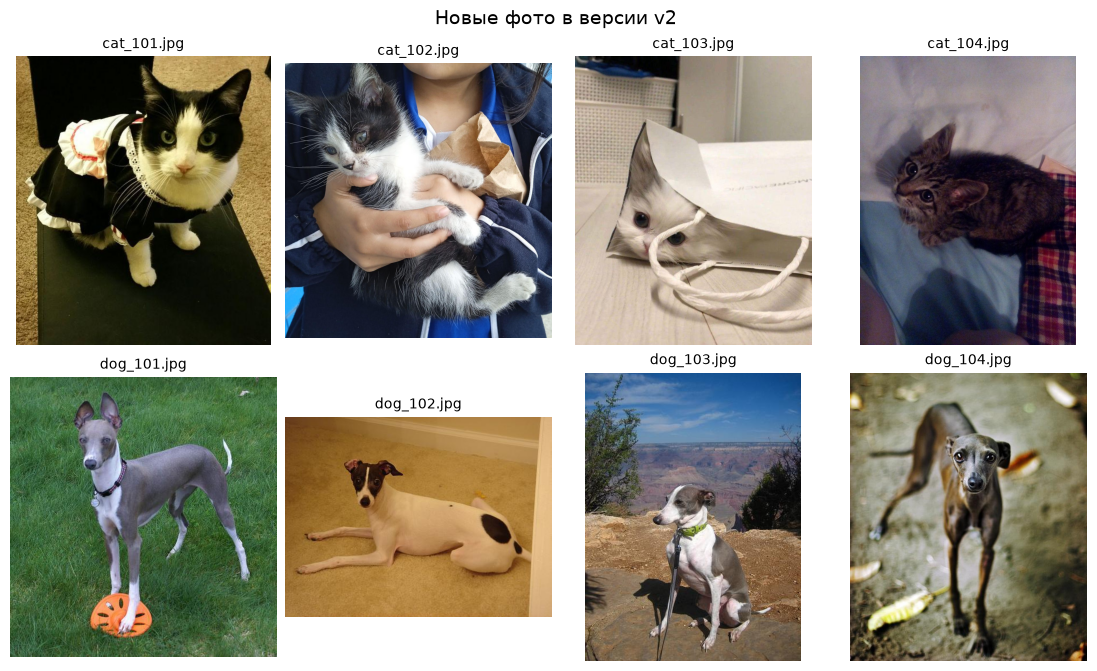

In [24]:
cats = [row for row in extended if row["label"] == "cat"]
dogs = [row for row in extended if row["label"] == "dog"]
gallery(dataset_dir / "images", cats[100:104] + dogs[100:104], "Новые фото в версии v2")

Проверяем, что первые 200 записей v2 совпадают с разметкой v1. Если они различаются, `assert` остановит выполнение.

In [25]:
assert extended[:len(labels)] == labels

Обновляем `labels.json` расширенного набора. В том же файле теперь 400 записей.

In [26]:
write_labels(dataset_dir, extended)

Снова выполняем `dvc add dataset`. DVC обновляет указатель `dataset.dvc` под содержимое расширенного набора.

In [27]:
!cd data && dvc add dataset

⠋ Checking graph
Adding...                                                                      
!


                                                                               
!
  0% Checking cache in '/home/dolotov-e/Documents/.cats-dogs-benchmark-check-mf
                                                                               
!
  0%|          |Adding dataset to cache            0/201 [00:00<?,     ?file/s]


!
Checking out ./data
100% Adding...|███████████████████████████████████████|1/1 [00:00,  7.35file/s]

To track the changes with git, run:

	git add dataset.dvc

To enable auto staging, run:

	dvc config core.autostage true


Отправляем v2 в хранилище командой `dvc push`. DVC добавляет новые файлы и обновлённую разметку. Общие для двух версий фотографии уже лежат в хранилище.

In [28]:
!cd data && dvc push dataset.dvc

Pushing
!
  0% Querying remote cache|                         |0/1 [00:00<?,    ?files/s]
                                                                               
!
  0% Querying remote cache|                         |0/1 [00:00<?,    ?files/s]
                                                                               
!
  0% Checking cache in '/home/dolotov-e/Documents/.cats-dogs-benchmark-check-mf
                                                                               
!
  0% Checking cache in '/home/dolotov-e/Documents/.cats-dogs-benchmark-check-mf
                                                                               
!
  0%|          |Pushing to local                     0/2 [00:00<?,     ?file/s]


Pushing


2 files pushed


Коммитим обновлённый `dataset.dvc` и ставим тег `dataset-v2`. Git теперь хранит историю двух указателей на одну и ту же рабочую папку.

In [29]:
!git -C data add dataset.dvc
!git -C data commit -m "Сохраняем датасет v2" && git -C data tag dataset-v2

[main 8069ff1] Сохраняем датасет v2
 1 file changed, 3 insertions(+), 3 deletions(-)


Команда `dvc status dataset.dvc` проверяет, совпадает ли рабочая папка с версией из текущего указателя.

In [30]:
!cd data && dvc status dataset.dvc

Data and pipelines are up to date.


Через `git show` читаем один и тот же файл `dataset.dvc` из двух коммитов. Сравниваем число JPEG и идентификаторы наборов.

In [31]:
import yaml
import pandas as pd

def snapshot(text):
    return yaml.safe_load(text)["outs"][0]

versions = []
for version in ("v1", "v2"):
    pointer = !git -C data show "dataset-{version}:dataset.dvc"
    saved = snapshot("\n".join(pointer))
    versions.append([version, saved["nfiles"] - 1, saved["nfiles"], saved["md5"][:8]])
display(pd.DataFrame(versions, columns=["Версия", "Фото", "Всего файлов", "ID данных"]))

,Версия,Фото,Всего файлов,ID данных
0,v1,200,201,175fac7b
1,v2,400,401,2e24de65


### Переключаем версии в одной папке

Сейчас в `dataset_dir` лежит v2. Возвращаем указатель из тега `dataset-v1` и выполняем `dvc pull`. Считаем JPEG в рабочей папке после восстановления.

In [32]:
!git -C data restore --source=dataset-v1 -- dataset.dvc
!cd data && dvc pull dataset.dvc
print("v1 ·", dataset_dir, "· фотографий:", len(list((dataset_dir / "images").glob("*.jpg"))))

Fetching


!
  0% Checking cache in '/home/dolotov-e/Documents/.cats-dogs-benchmark-check-mf
Fetching
Building workspace index                             |404 [00:00, 18.5kentry/s]
Comparing indexes                                    |404 [00:00, 56.5kentry/s]
Applying changes                                     |0.00 [00:00,     ?file/s]

Applying changes                                     |1.00 [00:00,  50.7file/s]


M       dataset/
1 file modified and 200 files deleted


v1 · data/dataset · фотографий: 200


Возвращаем указатель из тега `dataset-v2` и снова выполняем `dvc pull`. Считаем JPEG в той же папке.

In [33]:
!git -C data restore --source=dataset-v2 -- dataset.dvc
!cd data && dvc pull dataset.dvc
print("v2 ·", dataset_dir, "· фотографий:", len(list((dataset_dir / "images").glob("*.jpg"))))

Fetching
!
  0% Checking cache in '/home/dolotov-e/Documents/.cats-dogs-benchmark-check-mf


Fetching
Building workspace index                             |204 [00:00, 17.4kentry/s]
Comparing indexes                                    |404 [00:00, 62.8kentry/s]
Applying changes                                     |0.00 [00:00,     ?file/s]

Applying changes                                      |201 [00:00, 3.83kfile/s]


M       dataset/
1 file modified and 200 files added


v2 · data/dataset · фотографий: 400


<a id="labels"></a>

## 3. Инструмент для разметки

Читаем исходные метки и черновик. Это позволяет закрыть ноутбук и продолжить проверку с сохранёнными решениями.

In [34]:
def default_label(value):
    return value if value in ("cat", "dog") else "cat"

annotation = data / "annotation"
annotation.mkdir(parents=True, exist_ok=True)
draft = annotation / "draft.json"
rows = [dict(row, label=default_label(row.get("label"))) for row in extended]
saved = json.loads(draft.read_text()) if draft.exists() else {}
changes = {name: default_label(label) for name, label in saved.items()}

Создаём виджет изображения, счётчик и кнопки навигации. Начинаем с первой записи в списке.

In [35]:
import ipywidgets as widgets
from IPython.display import display

position = 0
picture = widgets.Image(format="jpeg", layout=widgets.Layout(max_width="440px"))
caption = widgets.Label()
back = widgets.Button(description="← Назад")
forward = widgets.Button(description="Далее →")
cat_button = widgets.Button(description="Кошка")
dog_button = widgets.Button(description="Собака")

При переходе читаем JPEG и показываем исходную метку и текущую метку с учётом черновика. На краях списка отключаем недоступную кнопку.

In [36]:
def show_photo():
    row = rows[position]
    name = row["name"]
    current = changes.get(name, row["label"])
    picture.value = (dataset_dir / "images" / name).read_bytes()
    caption.value = f'{position + 1}/{len(rows)} · {name} · Исходная метка: {row["label"]} · Текущая метка: {current}'
    cat_button.button_style = "success" if current == "cat" else ""
    dog_button.button_style = "success" if current == "dog" else ""
    back.disabled = position == 0
    forward.disabled = position == len(rows) - 1

def move(step):
    global position
    position = min(max(position + step, 0), len(rows) - 1)
    show_photo()

Описываем действие при выборе класса. Сохраняем исправление в черновик и переходим к следующей фотографии.

In [37]:
def mark(label):
    row = rows[position]
    if label == row["label"]:
        changes.pop(row["name"], None)
    else:
        changes[row["name"]] = label
    temporary = draft.with_suffix(".tmp")
    temporary.write_text(json.dumps(changes, indent=2), encoding="utf-8")
    temporary.replace(draft)
    move(1)

<a id="open-labeler"></a>

### Запускаем разметчик

Выполните ячейку и проверьте метки в форме под ней. Зелёная кнопка показывает текущий класс. Когда закончите, выполните следующую ячейку, чтобы сохранить итоговый `labels_reviewed.json`.

In [38]:
back.on_click(lambda _: move(-1))
forward.on_click(lambda _: move(1))
cat_button.on_click(lambda _: mark("cat"))
dog_button.on_click(lambda _: mark("dog"))
show_photo()
display(widgets.VBox([caption, widgets.HBox([back, cat_button, dog_button, forward]), picture]))

Для каждой фотографии берём выбранную метку. Сохраняем весь список из 400 записей в `labels_reviewed.json`.

In [39]:
reviewed = [dict(row, label=changes.get(row["name"], row["label"])) for row in rows]
export = annotation / "labels_reviewed.json"
export.write_text(json.dumps(reviewed, indent=2), encoding="utf-8")

47730

Сравниваем проверенные метки с исходными. Выводим число изменений и первое исправление, если оно есть.

In [40]:
edits = [(a, b) for a, b in zip(extended, reviewed) if a.get("label") != b["label"]]
print("Изменено меток:", len(edits))
if edits:
    old, new = edits[0]
    print(new["name"], old.get("label"), "→", new["label"])

Изменено меток: 0


Записываем проверенные метки в `labels.json` рабочей папки. Фотографии остаются на месте. Если исправлений нет, для обучения подходит сохранённая версия v2.

In [41]:
write_labels(dataset_dir, reviewed)
print("Исправлений для обучения:", len(edits))

Исправлений для обучения: 0


Если были исправления, обновляем указатель через `dvc add dataset`. Он теперь описывает тот же набор фотографий с проверенными метками.

In [42]:
if edits:
    !cd data && dvc add dataset

Если были исправления, отправляем версию с проверенными метками в хранилище DVC.

In [43]:
if edits:
    !cd data && dvc push dataset.dvc

Сохраняем указатель с исправленными метками отдельным коммитом.

In [44]:
if edits:
    !git -C data add dataset.dvc
    !git -C data commit -m "Сохраняем исправленные метки" -- dataset.dvc

<a id="training"></a>

## 4. Обучение моделей и сравнение в MLflow

Сравним Small CNN и ResNet18 на финальном наборе с проверенными метками. Обе модели получат одинаковые снимки для обучения и валидации. Победителя выберем по F1 на валидации, а тест оставим для итоговой оценки.

### Настройки обучения

`image_size` задаёт размер входного снимка, а `batch_size` задаёт число снимков на одном шаге обновления весов. Обе сети обучаются по 8 эпох. Одна эпоха означает один проход по всем обучающим фото. `lr` задаёт шаг оптимизатора, а `seed` фиксирует случайное разбиение и порядок перемешивания.

In [45]:
params = {"seed": 42, "image_size": 96, "batch_size": 32, "threads": 2}
models = {
    "small_cnn": {"epochs": 8, "lr": 0.001},
    "resnet18": {"epochs": 8, "lr": 0.001},
}

Функция `pixels` готовит снимки к подаче в модель. Она исправляет ориентацию, переводит фото в RGB, меняет размер и приводит значения пикселей к диапазону от −1 до 1. Будем использовать её при обучении и при запуске ONNX.

In [46]:
import numpy as np
from PIL import Image
from deployment.app.pixels import pixels

### Делим фотографии на выборки

| Выборка | Фото | Для чего нужна |
| --- | ---: | --- |
| Обучение | 280 | Обновляем веса сети |
| Валидация | 60 | Выбираем лучшую эпоху и сравниваем модели |
| Тест | 60 | Оцениваем модель после выбора |

Сначала выделяем 30% снимков, затем делим эту часть пополам. Параметр `stratify` сохраняет примерно одинаковые пропорции кошек и собак во всех трёх выборках.

In [47]:
from sklearn.model_selection import train_test_split

labels_by_name = {row["name"]: row["label"] for row in reviewed}
names = sorted(labels_by_name)
train_names, holdout = train_test_split(
    names, test_size=0.30, stratify=[labels_by_name[name] for name in names],
    random_state=params["seed"],
)
val_names, test_names = train_test_split(
    holdout, test_size=0.5, stratify=[labels_by_name[name] for name in holdout],
    random_state=params["seed"],
)
splits = {"train": train_names, "val": val_names, "test": test_names}

### Сколько кошек и собак в каждой выборке

Столбцы показывают количество фотографий по проверенным меткам. По ним видно, сохранились ли пропорции классов после разделения.

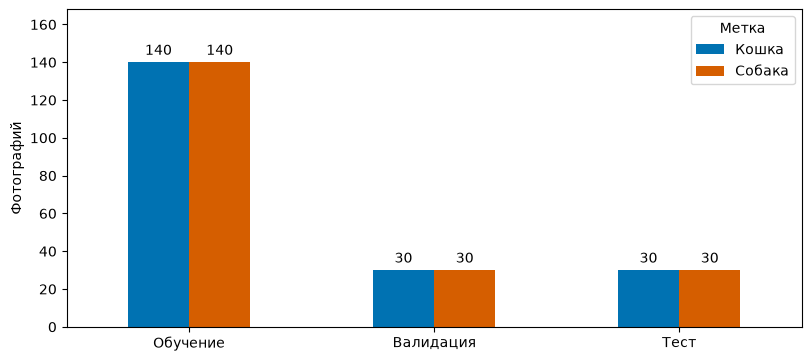

In [48]:
class_names = {"cat": "Кошка", "dog": "Собака"}
split_names = {"train": "Обучение", "val": "Валидация", "test": "Тест"}

counts = pd.DataFrame({
    split_names[split]: {
        title: sum(labels_by_name[name] == label for name in names)
        for label, title in class_names.items()
    }
    for split, names in splits.items()
}).T

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
counts.plot.bar(ax=ax, color=["#0072B2", "#D55E00"], rot=0)
for bars in ax.containers:
    ax.bar_label(bars, padding=3)
ax.set(ylabel="Фотографий", ylim=(0, counts.to_numpy().max() * 1.2))
ax.legend(title="Метка")
plt.show()

В обучение попало по **140** фото каждого класса. В валидацию и тест попало по **30** фото каждого класса.

### Готовим входы PyTorch

У одного снимка три цветовых канала и размер 96 × 96. Каждому снимку сопоставляем номер класса, где 0 означает кошку, а 1 собаку. `TensorDataset` хранит пары «фото и правильный класс». Тестовые фото подготовим после выбора модели.

In [49]:
import torch
from torch.utils.data import TensorDataset

class_index = {"cat": 0, "dog": 1}
classes = list(class_index)

def photo_array(name):
    with Image.open(dataset_dir / "images" / name) as photo:
        return pixels(photo, params["image_size"])

def load_samples(names):
    images = np.stack([photo_array(name) for name in names])
    targets = torch.tensor([class_index[labels_by_name[name]] for name in names])
    return TensorDataset(torch.from_numpy(images), targets)

train_data = load_samples(splits["train"])
val_data = load_samples(splits["val"])

### Выбираем архитектуры для сравнения

Small CNN выделяет признаки тремя свёрточными слоями. ResNet18 глубже и использует остаточные связи. У обеих сетей два выхода, по одной оценке на класс. Веса начинаем обучать с нуля. Фиксированный `seed` задаёт начальное состояние генераторов случайных чисел.

In [50]:
from torch import nn
from torchvision.models import resnet18


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)


def small_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 2),
    )


def build_model(name):
    if name == "small_cnn":
        return small_cnn()
    if name == "resnet18":
        return resnet18(weights=None, num_classes=2)
    raise ValueError(name)

### Собираем снимки в группы

`DataLoader` подаёт снимки в модель группами по `batch_size`. На валидации порядок фиксирован. Для обучения ниже создадим перемешиваемую выборку с одним и тем же начальным `seed` для каждой модели.

In [51]:
from torch.utils.data import DataLoader

torch.set_num_threads(params["threads"])
loss_fn = nn.CrossEntropyLoss()
val_loader = DataLoader(val_data, batch_size=params["batch_size"])

### Оцениваем модель после каждой эпохи

На валидации сеть только предсказывает классы. `model.eval()` переводит её в режим предсказания, а `torch.inference_mode()` отключает вычисление градиентов. Из двух оценок выбираем класс с наибольшей.

Точность показывает долю верных ответов. F1 учитывает пропущенные снимки класса и снимки, ошибочно отнесённые к нему. Macro-F1 усредняет F1 кошек и собак с равным весом. По нему будем выбирать лучшую эпоху.

In [52]:
from sklearn.metrics import accuracy_score, f1_score

def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    truth, predictions = [], []
    with torch.inference_mode():
        for images, labels in loader:
            scores = model(images)
            total_loss += loss_fn(scores, labels).item() * len(labels)
            truth.extend(labels.tolist())
            predictions.extend(scores.argmax(dim=1).tolist())
    return {
        "loss": total_loss / len(truth),
        "accuracy": accuracy_score(truth, predictions),
        "macro_f1": f1_score(truth, predictions, average="macro", zero_division=0),
    }

### Обучаем сеть

Внутри каждой эпохи модель предсказывает классы для группы фото. `loss_fn` измеряет ошибку, `backward()` вычисляет градиенты, а `optimizer.step()` обновляет веса. Перед каждой новой группой вызываем `zero_grad()`, чтобы очистить градиенты предыдущей.

После эпохи записываем ошибку обучения и показатели валидации в MLflow. Если F1 вырос, сохраняем копию текущих весов. После последней эпохи восстанавливаем веса с лучшим F1.

In [53]:
import copy
import mlflow

def fit(model, train_loader, val_loader, epochs, lr, loss_fn):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    best_epoch, best_f1, best_weights = 0, -1.0, None

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for images, labels in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(images), labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(labels)

        train_loss = total_loss / len(train_loader.dataset)
        val_metrics = evaluate(model, val_loader, loss_fn)
        val_f1 = val_metrics["macro_f1"]
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metrics({f"val_{key}": value for key, value in val_metrics.items()}, step=epoch)
        print(f"Эпоха {epoch}/{epochs} · F1 на валидации {val_f1:.3f}", flush=True)

        if val_f1 > best_f1:
            best_epoch, best_f1 = epoch, val_f1
            best_weights = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_weights)
    return best_epoch, best_f1

### Настраиваем MLflow

Эксперимент `cats-dogs` объединяет сравниваемые запуски. Внутри него каждая модель получает отдельную запись. `dataset_id` берём из `dataset.dvc`, чтобы у запуска была отметка о конкретной версии фотографий и меток.

In [54]:
from uuid import uuid4

mlflow.set_tracking_uri(f"sqlite:///{(data / 'training_mlflow.db').resolve()}")
experiment_name = "cats-dogs"
if mlflow.get_experiment_by_name(experiment_name) is None:
    mlflow.create_experiment(experiment_name, artifact_location=(data / "mlruns").resolve().as_uri())
mlflow.set_experiment(experiment_name)
client = mlflow.MlflowClient()
dataset_id = snapshot(dataset_pointer.read_text())["md5"]

2026/11/22 23:14:38 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/22 23:14:38 INFO mlflow.store.db.utils: Updating database tables


### Запускаем обе модели

Каждое обучение идёт внутри `mlflow.start_run`. Общая метка `series` позволит потом выбрать эти два запуска из журнала.

- `log_params` сохраняет настройки и идентификатор датасета.
- `log_metrics` записывает лучшую эпоху и её F1. Показатели после каждой эпохи записывает функция `fit`.
- `log_artifact` и `log_dict` сохраняют веса и списки снимков по выборкам.

In [55]:
series = uuid4().hex[:12]
out = data / "training_outputs"
out.mkdir(exist_ok=True)

for architecture, settings in models.items():
    print("Обучаем", architecture, flush=True)
    seed_everything(params["seed"])
    model = build_model(architecture)
    generator = torch.Generator().manual_seed(params["seed"])
    train_loader = DataLoader(train_data, batch_size=params["batch_size"], shuffle=True, generator=generator)

    with mlflow.start_run(run_name=architecture, tags={"series": series}):
        mlflow.log_params({"architecture": architecture, "dataset_snapshot": dataset_id,
                           "train_size": len(train_data), **params, **settings})
        epoch, score = fit(model, train_loader, val_loader, loss_fn=loss_fn, **settings)
        mlflow.log_metrics({"best_epoch": epoch, "best_val_macro_f1": score})
        weights = out / f"{architecture}.pt"
        torch.save(model.state_dict(), weights)
        mlflow.log_artifact(str(weights))
        mlflow.log_dict(splits, "splits.json")

Обучаем small_cnn


Эпоха 1/8 · F1 на валидации 0.472


Эпоха 2/8 · F1 на валидации 0.373


Эпоха 3/8 · F1 на валидации 0.389


Эпоха 4/8 · F1 на валидации 0.403


Эпоха 5/8 · F1 на валидации 0.433


... (8 outputs left out)

Эпоха 5/8 · F1 на валидации 0.479


Эпоха 6/8 · F1 на валидации 0.401


Эпоха 7/8 · F1 на валидации 0.451


Эпоха 8/8 · F1 на валидации 0.446


### Читаем результаты из MLflow

Выбираем запуски по метке `series`. Так в таблицу попадут результаты этого сравнения даже после нескольких запусков ячейки обучения.

In [56]:
query = f"tags.series = '{series}'"
history = mlflow.search_runs(experiment_names=[experiment_name], filter_string=query)
assert len(history) == len(models), "В MLflow должен быть запуск для каждой модели"

В таблице ищем наибольший F1. Столбец «Лучшая эпоха» показывает, после какого прохода по данным получены сохранённые веса.

In [57]:
table = history[["tags.mlflow.runName", "params.train_size",
                 "metrics.best_epoch", "metrics.best_val_macro_f1"]].copy()
table.columns = ["Запуск", "Фото в обучении", "Лучшая эпоха", "F1 на валидации"]
display(table.sort_values("F1 на валидации", ascending=False).round(3))
print("Фильтр серии:", query)

,Запуск,Фото в обучении,Лучшая эпоха,F1 на валидации
0,resnet18,280,2.0,0.617
1,small_cnn,280,8.0,0.520


Фильтр серии: tags.series = 'e8749a4b4ea7'


По графику ошибки смотрим, как менялось обучение. По F1 на валидации видим, на какой эпохе модель лучше справлялась с отложенными снимками.

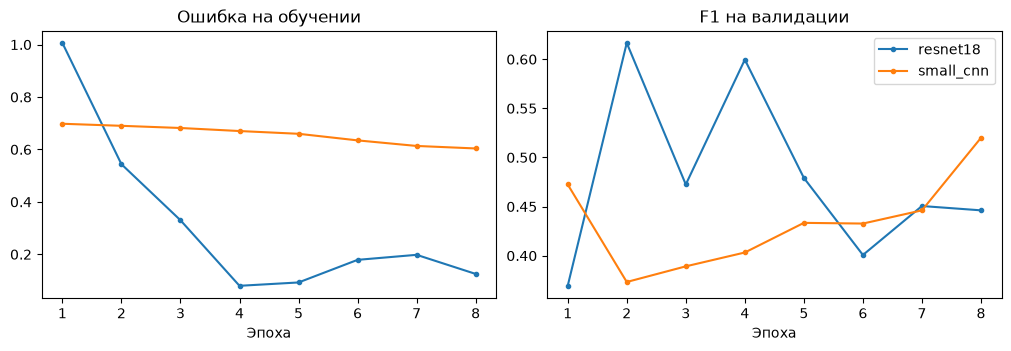

In [58]:
runs = dict(zip(history["tags.mlflow.runName"], history["run_id"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
for ax, metric, title in zip(axes, ["train_loss", "val_macro_f1"], ["Ошибка на обучении", "F1 на валидации"]):
    for name, run_id in runs.items():
        metric_history = sorted(client.get_metric_history(run_id, metric), key=lambda item: item.step)
        ax.plot([m.step for m in metric_history], [m.value for m in metric_history], marker=".", label=name)
    ax.set(xlabel="Эпоха", title=title)
axes[1].legend()
plt.show()

У ResNet18 лучший F1 на валидации получился на **2-й эпохе**, у `small_cnn` на **8-й**. К последней эпохе F1 у ResNet18 снизился с 0,617 до 0,446. Для сравнения берём веса лучшей эпохи.

### Где ошибается каждая модель

Загружаем лучшие веса обеих сетей и пропускаем через них одни и те же валидационные фотографии. В каждой матрице строки показывают метки из датасета, столбцы показывают ответы модели. Числа на диагонали показывают верные ответы. Остальные клетки показывают, сколько раз сеть перепутала классы.

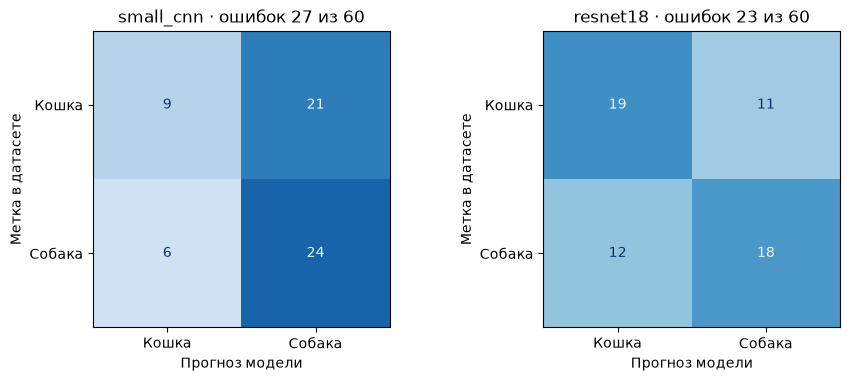

In [59]:
from sklearn.metrics import ConfusionMatrixDisplay

val_truth = [labels_by_name[name] for name in splits["val"]]
validation_predictions = {}
fig, axes = plt.subplots(1, len(models), figsize=(9, 3.7), layout="constrained")
scale_max = max(val_truth.count(label) for label in classes)

for ax, name in zip(axes, models):
    model = build_model(name)
    model.load_state_dict(torch.load(out / f"{name}.pt", map_location="cpu", weights_only=True))
    model.eval()
    with torch.inference_mode():
        indices = torch.cat([model(images).argmax(dim=1) for images, _ in val_loader])
    predictions = [classes[index] for index in indices.tolist()]
    validation_predictions[name] = predictions
    errors = sum(actual != predicted for actual, predicted in zip(val_truth, predictions))

    ConfusionMatrixDisplay.from_predictions(
        val_truth, predictions, labels=classes, display_labels=list(class_names.values()),
        ax=ax, colorbar=False, cmap="Blues", im_kw={"vmin": 0, "vmax": scale_max},
    )
    ax.set(title=f"{name} · ошибок {errors} из {len(val_truth)}",
           xlabel="Прогноз модели", ylabel="Метка в датасете")
plt.show()

Из 60 снимков ResNet18 ошиблась на **23**, а `small_cnn` на **27**. `small_cnn` чаще принимала кошек за собак (**21** раз), а ResNet18 чаще принимала собак за кошек (**12** раз).

### Фотографии, на которых модели ошиблись

Показываем до четырёх случайных ошибок каждой сети. Фиксируем `seed`, чтобы при тех же предсказаниях увидеть те же снимки. Под каждым именем файла указаны метка из датасета и прогноз модели.

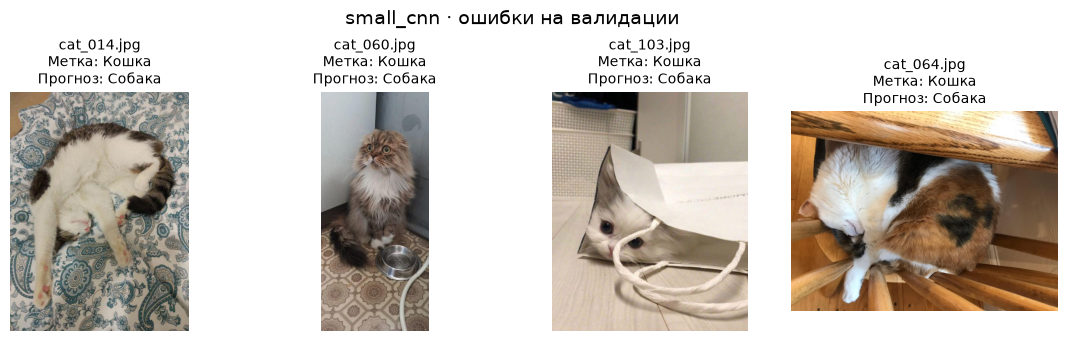

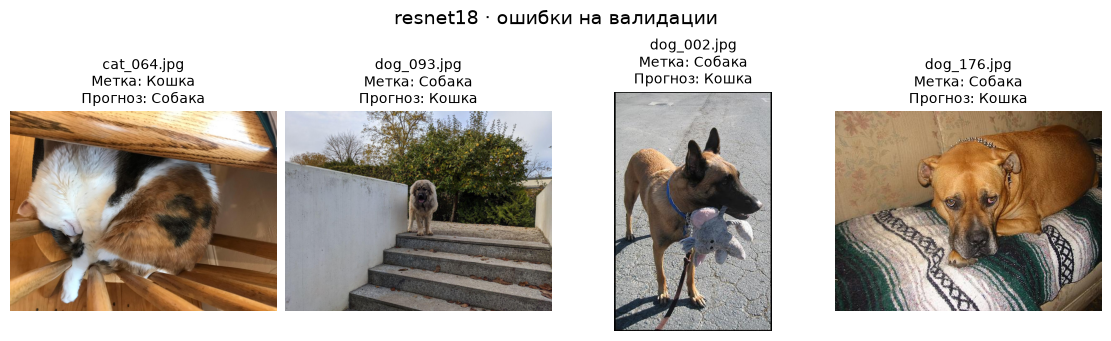

In [60]:
def show_errors(names, truth, predictions, title):
    mistakes = []
    for name, actual, predicted in zip(names, truth, predictions):
        if actual != predicted:
            caption = f"{name}\nМетка: {class_names[actual]}\nПрогноз: {class_names[predicted]}"
            mistakes.append({"name": name, "caption": caption})

    if not mistakes:
        print(f"{title}. Ошибок нет.")
        return
    examples = random.Random(params["seed"]).sample(mistakes, min(4, len(mistakes)))
    gallery(dataset_dir / "images", examples, title)

for name, predictions in validation_predictions.items():
    show_errors(splits["val"], val_truth, predictions, f"{name} · ошибки на валидации")

**Пример из валидации, `cat_064.jpg`.** Обе сети приняли кошку за собаку. Кошка свернулась на стуле и прикрыла мордочку лапой. В таком ракурсе очертания головы и тела видны хуже, и это могло затруднить распознавание.

В следующий раздел передаём сеть с наибольшим F1 на валидации. Её веса уже сохранены в файле `.pt`.

In [61]:
validation_f1 = history.set_index("tags.mlflow.runName")["metrics.best_val_macro_f1"]
winner = max(models, key=validation_f1.get)
best_f1 = validation_f1[winner]
print("По F1 на валидации выбрали", winner)

По F1 на валидации выбрали resnet18


### Проверяем версию датасета

Сверяем `dataset_snapshot` у победителя с указателем DVC. Совпадающий идентификатор связывает результат обучения с той версией фотографий и меток, которую мы подготовили.

In [62]:
best = mlflow.get_run(runs[winner])
assert best.data.params["dataset_snapshot"] == dataset_id
print("Версия датасета:", dataset_id)

Версия датасета: 2e24de6559fff7425cb802528423aae4.dir


Показываем артефакты победителя. Файл `.pt` содержит веса, а `splits.json` перечисляет снимки по выборкам.

In [63]:
print("Файлы запуска:", [file.path for file in client.list_artifacts(best.info.run_id)])

Файлы запуска: ['resnet18.pt', 'splits.json']


<a id="quantization"></a>

## 5. Экспорт в ONNX и квантизация

ONNX позволяет запускать обученную модель в ONNX Runtime. Сначала сохраним модель в FP32. Затем получим INT8, где часть вычислений использует 8-битные целые числа. Сравним, как изменились размер файла, время ответа и F1.

### Экспортируем FP32

Считываем лучшие веса. Чтобы экспортировать модель, подаём один подготовленный снимок как пример входа. `[None]` добавляет размер группы, поэтому вход имеет форму `(1, 3, 96, 96)`. Это один снимок с тремя каналами, высотой и шириной по 96 пикселей.

In [64]:
weights = out / f"{winner}.pt"
model = build_model(winner)
model.load_state_dict(torch.load(weights, map_location="cpu", weights_only=True))
model.eval()

def photo_batch(name):
    return photo_array(name)[None]

work = data / "onnx_outputs"
work.mkdir(exist_ok=True)
fp32_path = work / "fp32.onnx"
example = torch.from_numpy(photo_batch(splits["val"][0]))
torch.onnx.export(model, example, str(fp32_path), input_names=["image"],
                  output_names=["logits"], opset_version=17, dynamo=False)

/tmp/ipykernel_106129/3052489542.py:13: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter will be the default. To switch now, set dynamo=True in torch.onnx.export. This new exporter supports features like exporting LLMs with DynamicCache. We encourage you to try it and share feedback to help improve the experience. Learn more about the new export logic: https://pytorch.org/docs/stable/onnx_dynamo.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html.
  torch.onnx.export(model, example, str(fp32_path), input_names=["image"],


### Подбираем диапазоны для INT8

Для калибровки берём 64 фото из обучающей выборки. ONNX Runtime пропускает их через модель и определяет, какие диапазоны чисел предстоит представить в INT8. `CalibrationPhotos` передаёт снимки по одному в поле `image`. Так называется вход экспортированной модели.

In [65]:
from onnxruntime.quantization import CalibrationDataReader

calibration = splits["train"][:64]

class CalibrationPhotos(CalibrationDataReader):
    def __init__(self, names):
        self.samples = iter({"image": photo_batch(name)} for name in names)

    def get_next(self):
        return next(self.samples, None)

### Создаём INT8

`quant_pre_process` уточняет размеры промежуточных массивов. Затем `quantize_static` создаёт `int8.onnx` с учётом калибровочных фото. В этом примере преобразуем свёрточные и линейные операции.

In [66]:
from onnxruntime.quantization import quantize_static
from onnxruntime.quantization.shape_inference import quant_pre_process

prepared = work / "prepared.onnx"
int8_path = work / "int8.onnx"
quant_pre_process(str(fp32_path), str(prepared), skip_symbolic_shape=True)
quantize_static(str(prepared), str(int8_path), CalibrationPhotos(calibration),
                per_channel=True, op_types_to_quantize=["Conv", "Gemm", "MatMul"])

### Измеряем время на CPU

Сравниваем уже экспортированные FP32 и INT8 одной модели на одних и тех же валидационных снимках. Для каждого формата используем один поток. Пять вызовов в начале каждого замера прогревают модель. Затем измеряем время предсказания для каждого заранее подготовленного снимка.

В прошлых прогонах данные и веса отличались, а для каждого формата мы делали только одну серию замеров. На время также может влиять фоновая нагрузка. По двум прогонам трудно сказать, почему поменялся лидер.

In [67]:
import onnxruntime as ort

options = ort.SessionOptions()
options.intra_op_num_threads = 1
options.inter_op_num_threads = 1
files = {"FP32": fp32_path, "INT8": int8_path}
sessions = {
    name: ort.InferenceSession(str(path), options, providers=["CPUExecutionProvider"])
    for name, path in files.items()
}

def predict(runtime, image):
    scores = runtime.run(None, {"image": image})[0][0]
    return classes[scores.argmax()]

def measure_latency(runtime, images):
    for image in images[:5]:
        predict(runtime, image)

    times_ms = []
    for image in images:
        start = time.perf_counter()
        predict(runtime, image)
        times_ms.append((time.perf_counter() - start) * 1000)
    return float(np.median(times_ms))

### Смотрим разброс времени

Проводим 12 раундов на тех же снимках. В нечётных раундах начинаем с FP32, в чётных с INT8. Для каждого раунда записываем медианное время одного предсказания.

In [68]:
val_names = splits["val"]
val_images = [photo_batch(name) for name in val_names]
val_truth = [labels_by_name[name] for name in val_names]

formats = list(sessions)
round_count = 12
latencies = {name: [] for name in formats}
for round_index in range(round_count):
    order = formats if round_index % 2 == 0 else formats[::-1]
    for name in order:
        latencies[name].append(measure_latency(sessions[name], val_images))

benchmark = pd.DataFrame(latencies, index=range(1, round_count + 1))

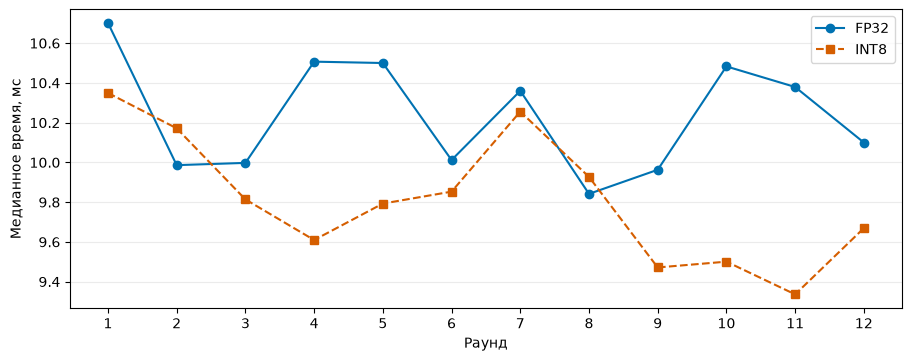

In [69]:
fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
for name, color, marker, style in zip(formats, ["#0072B2", "#D55E00"], ["o", "s"], ["-", "--"]):
    ax.plot(benchmark.index, benchmark[name], color=color, marker=marker, linestyle=style, label=name)

ax.set(xlabel="Раунд", ylabel="Медианное время, мс", xticks=benchmark.index)
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.show()

Каждая точка показывает медиану по 60 снимкам. У FP32 медиана менялась от **9,84 до 10,70 мс**, у INT8 от **9,34 до 10,35 мс**. Диапазоны пересекаются. INT8 был быстрее в **10** раундах, FP32 в **2**.

### Сводим результаты

Типичное время для каждого формата считаем как медиану по 12 раундам. Рядом показываем самый быстрый и самый медленный раунды. F1 считаем по предсказаниям на тех же снимках.

In [70]:
results = {}
for name, runtime in sessions.items():
    predictions = [predict(runtime, image) for image in val_images]
    results[name] = {
        "bytes": files[name].stat().st_size,
        "p50_ms": float(benchmark[name].median()),
        "val_macro_f1": f1_score(val_truth, predictions, average="macro", zero_division=0),
    }

table = pd.DataFrame.from_dict(results, orient="index")
table.columns = ["Размер, байт", "Медиана раундов, мс", "F1 на валидации"]
table["Мин. раунд, мс"] = benchmark.min()
table["Макс. раунд, мс"] = benchmark.max()
display(table.round(3))

,"Размер, байт","Медиана раундов, мс",F1 на валидации,"Мин. раунд, мс","Макс. раунд, мс"
FP32,44700645,10.230,0.617,9.842,10.702
INT8,11300909,9.803,0.617,9.336,10.349


### Что изменила квантизация

Сравниваем размер файла, типичное время предсказания на CPU и macro-F1 на валидации. Точки всех раундов видны на предыдущем графике.

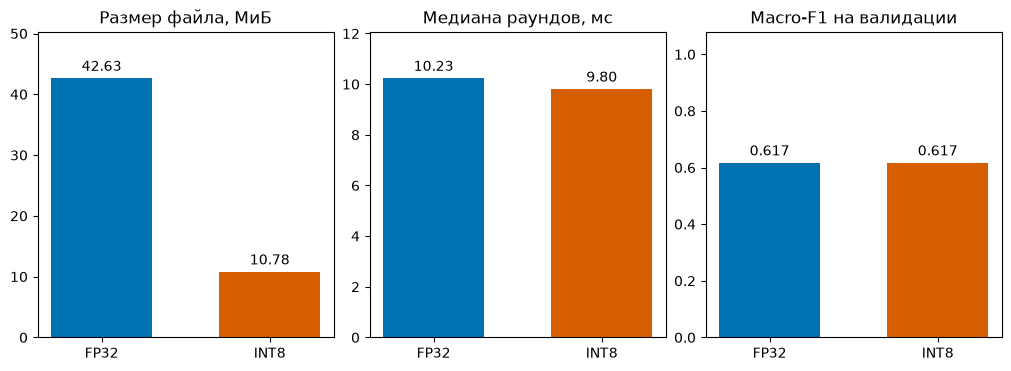

In [71]:
comparisons = [
    ("Размер файла, МиБ", [results[name]["bytes"] / 2**20 for name in formats], "%.2f"),
    ("Медиана раундов, мс", [results[name]["p50_ms"] for name in formats], "%.2f"),
    ("Macro-F1 на валидации", [results[name]["val_macro_f1"] for name in formats], "%.3f"),
]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), layout="constrained")
for ax, (title, values, number_format) in zip(axes, comparisons):
    bars = ax.bar(formats, values, color=["#0072B2", "#D55E00"], width=0.6)
    ax.bar_label(bars, fmt=number_format, padding=3)
    ax.set_title(title)
    ax.set_ylim(0, 1.08 if number_format == "%.3f" else max(values) * 1.18)
plt.show()

INT8 уменьшил размер файла с **42,6 до 10,8 МиБ**. Macro-F1 на валидации остался на уровне **0,617**. Медиана по 12 раундам на CPU изменилась с **10,23 до 9,80 мс**. Выбрали **INT8**, потому что файл стал меньше, ответы быстрее, а F1 сохранился.

### Выбираем формат

Выбираем INT8, если файл меньше, медиана по раундам ниже, а падение F1 укладывается в 0,02. Например, переход с 0,80 на 0,79 проходит порог по качеству, а переход с 0,80 на 0,77 превышает его.

In [72]:
fp32_metrics = results["FP32"]
int8_metrics = results["INT8"]
smaller = int8_metrics["bytes"] < fp32_metrics["bytes"]
faster = int8_metrics["p50_ms"] < fp32_metrics["p50_ms"]
f1_drop = fp32_metrics["val_macro_f1"] - int8_metrics["val_macro_f1"]

selected = "INT8" if smaller and faster and f1_drop <= 0.02 else "FP32"
print("Выбран формат", selected)

Выбран формат INT8


Формат уже выбран. Теперь проверяем только его на отложенных фото и считаем долю верных ответов и macro-F1. Эти снимки дают независимую оценку после выбора модели и формата.

In [73]:
test_names = splits["test"]
test_truth = [labels_by_name[name] for name in test_names]
test_predictions = [predict(sessions[selected], photo_batch(name)) for name in test_names]
test_accuracy = accuracy_score(test_truth, test_predictions)
test_f1 = f1_score(test_truth, test_predictions, average="macro", zero_division=0)
results[selected].update(test_accuracy=test_accuracy, test_macro_f1=test_f1)

### Ошибки выбранной модели на тесте

Смотрим примеры ошибок уже после выбора модели и формата. Тестовую выборку открываем после обучения и выбора формата.

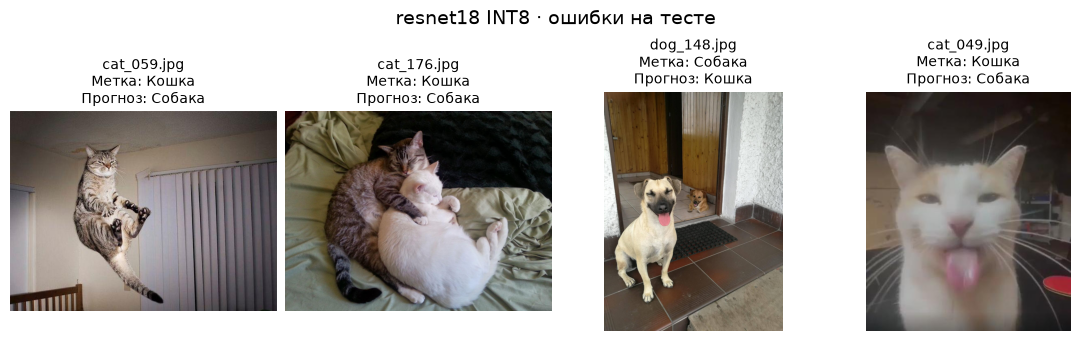

In [74]:
show_errors(test_names, test_truth, test_predictions, f"{winner} {selected} · ошибки на тесте")

**Пример из теста, `cat_049.jpg`.** ResNet18 в формате INT8 приняла кошку за собаку. На снимке крупным планом видна мордочка, а её контуры размыты. Размытость могла скрыть мелкие детали, которые помогают различать классы.

Записываем выбранный вариант в `model.onnx`. В `metadata.json` сохраняем порядок классов и размер входа, чтобы при загрузке модели правильно подготовить фото и прочитать выходы. Там же сохраняем идентификаторы датасета и запуска.

In [75]:
import hashlib

bundle = Path("deployment/app/bundle")
bundle.mkdir(parents=True, exist_ok=True)
model_path = bundle / "model.onnx"
shutil.copyfile(files[selected], model_path)
run_id = runs[winner]

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

meta = {"winner": winner, "variant": selected, "mlflow_run_id": run_id,
        "classes": classes, "image_size": params["image_size"], "dataset_snapshot": dataset_id,
        "checkpoint_sha256": digest(weights), "onnx_sha256": digest(model_path)}
(bundle / "metadata.json").write_text(json.dumps(meta, indent=2))

401

Добавляем сравнение FP32 и INT8 к запуску победителя. В отчёте сохраняем время каждого раунда, сводные метрики и ссылку на выбранный формат.

In [76]:
summary = work / "comparison.json"
benchmark_report = {"images_per_round": len(val_images), "rounds_ms": benchmark.to_dict(orient="list")}
summary.write_text(json.dumps({"deployment": meta, "results": results, "benchmark": benchmark_report}, indent=2))
for name, metrics in results.items():
    for metric, value in metrics.items():
        client.log_metric(run_id, f"{name.lower()}_{metric}", float(value))
client.log_artifact(run_id, str(summary), "inference")
client.log_artifact(run_id, str(model_path), "inference")

## Итог

В этом прогоне победила **ResNet18** с macro-F1 **0,617** на валидации. Из 60 снимков ResNet18 ошиблась на **23**, а `small_cnn` на **27**. `small_cnn` чаще принимала кошек за собак (**21** раз), а ResNet18 чаще принимала собак за кошек (**12** раз).

FP32 был быстрее в двух раундах, и диапазоны времени пересеклись. Для выбора формата сравнили типичное время ответа, то есть медиану по всем 12 раундам. У INT8 она составила **9,80 мс**, у FP32 **10,23 мс**. После квантизации файл уменьшился с **42,6 до 10,8 МиБ**, а macro-F1 на валидации остался **0,617**. По этим трём результатам выбрали **INT8**.

На отложенном тесте модель правильно классифицировала **56,7%** фотографий и получила macro-F1 **0,566**.